<a href="https://colab.research.google.com/github/Yash-Raj11/i3-stego-immunization/blob/main/notebooks/sd_demo_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# I3 — Stable Diffusion before / after demo (Google Colab)

Runs the whole demo on a free cloud GPU, so your laptop does no heavy work.

1. **Runtime → Change runtime type → T4 GPU → Save**
2. **Runtime → Run all** (or run the cells one by one)
3. Total time on a T4: about 10–15 minutes (most of it is the one-time ~4.5 GB model download)

Results appear at the bottom and are downloaded as a zip.

In [1]:
# 1. Check that a GPU is attached
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "NO GPU: Runtime > Change runtime type > T4 GPU"

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
# 2. Get the code from GitHub and install it
REPO = "https://github.com/Yash-Raj11/i3-stego-immunization.git"
%cd /content
!rm -rf i3 && git clone -q --depth 1 $REPO i3
%cd i3
!pip install -q -e ".[sd]"
!python scripts/download_models.py
!i3 keygen   # fresh demo keys for this Colab session (your real keys stay on your laptop)

/content
/content/i3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 13.7 MB/s eta 0:00:00
  Building editable for i3-stego-immunization (pyproject.toml) ... done
-> taesd_encoder.pth  (https://raw.githubusercontent.com/madebyollin/taesd/main/taesd_encoder.pth)
   4.91 MB  sha256=15bc6128f0ac51c6...
-> taesd_decoder.pth  (https://raw.githubusercontent.com/madebyollin/taesd/main/taesd_decoder.pth)
   4.91 MB  sha256=02873377c3f4659c...
-> face_detection_yunet_2023mar.onnx  (https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx)
   0.23 MB  sha256=8f2383e4dd3cfbb4...

All models ready.
keys written to keys/  - keep i3_secret.key and ed25519_private.pem private (they are git-ignored)


## 3. Choose the photo
Run the next cell as is to use the sample photo, or set `USE_MY_PHOTO = True` to upload your own.
Only use photos you have permission to use.

In [3]:
USE_MY_PHOTO = False
PHOTO = "assets/sample_astronaut.png"
if USE_MY_PHOTO:
    from google.colab import files
    up = files.upload()
    PHOTO = list(up.keys())[0]
print("photo:", PHOTO)

photo: assets/sample_astronaut.png


## 4. Run the demo
Settings you can change:
- `REFINE_STEPS`: steps against the real Stable Diffusion encoder (40 is a good GPU default; more = stronger, slower)
- `FACE_PSNR`: visibility limit on the face (32 default; lower = stronger protection but more visible)
- `MODE`: `untargeted` or `targeted` (try both)

In [4]:
REFINE_STEPS = 40
FACE_PSNR = 32
MODE = "untargeted"
OUT = "reports/colab_demo"
!i3 demo "$PHOTO" --owner demo@example.com --config configs/sd_demo.yaml --out $OUT \
    --refine-steps $REFINE_STEPS --face-psnr $FACE_PSNR --mode $MODE

INFO image 512x512 | faces: ['yunet'] | surrogate: taesd | device: cuda
INFO stage 1: 150 steps against taesd
INFO step   0/150  L_adv -0.0438  L_wm 0.0180  (9.5 s/step, ~1408 s left)
INFO step  10/150  L_adv -0.1000  L_wm 0.0569  (1.0 s/step, ~144 s left)
INFO step  20/150  L_adv -0.0524  L_wm 0.0424  (0.6 s/step, ~80 s left)
INFO step  30/150  L_adv -0.0293  L_wm 0.2230  (0.5 s/step, ~55 s left)
INFO step  40/150  L_adv -0.0466  L_wm 0.2419  (0.4 s/step, ~42 s left)
INFO step  50/150  L_adv -0.0620  L_wm 0.0304  (0.3 s/step, ~34 s left)
INFO step  60/150  L_adv -0.0543  L_wm 0.0948  (0.3 s/step, ~27 s left)
INFO step  70/150  L_adv -0.0799  L_wm 0.0075  (0.3 s/step, ~22 s left)
INFO step  80/150  L_adv -0.0808  L_wm 0.0000  (0.3 s/step, ~18 s left)
INFO step  90/150  L_adv -0.0543  L_wm 0.0079  (0.3 s/step, ~15 s left)
INFO step 100/150  L_adv -0.0931  L_wm 0.0681  (0.2 s/step, ~12 s left)
INFO step 110/150  L_adv -0.0905  L_wm 0.0933  (0.2 s/step, ~9 s left)
INFO step 120/150  L_adv

# Stable Diffusion morph test

- input size [512, 512], protected vs original: PSNR 40.23 dB, face PSNR 32.15 dB
- same prompt, seed and settings for both images; metrics on the face region of the ORIGINAL input
- face PSNR vs input: higher = the edit kept the face. A large drop for the protected photo = immunisation works.
- det: YuNet face-detector confidence on the edited image (0 = no face found).

| edit | face PSNR (orig → edit) | face PSNR (protected → edit) | drop dB | SSIM orig / prot | det orig / prot |
|---|---|---|---|---|---|
| img2img_s0.3 | 18.12 | 15.41 | **2.71** | 0.5548 / 0.4304 | 0.921 / 0.921 |
| img2img_s0.5 | 15.81 | 15.77 | **0.04** | 0.4136 / 0.3731 | 0.91 / 0.916 |
| inpaint_scene | 25.06 | 23.44 | **1.62** | 0.7509 / 0.6821 | 0.931 / 0.929 |

Hero figure (`before_after.png`) uses: **img2img_s0.3**


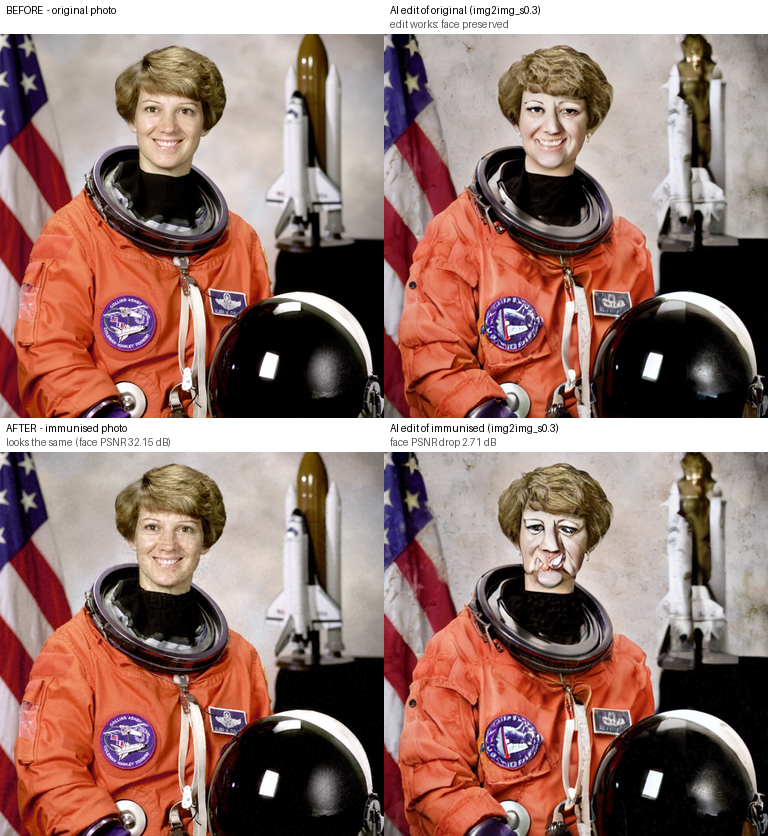

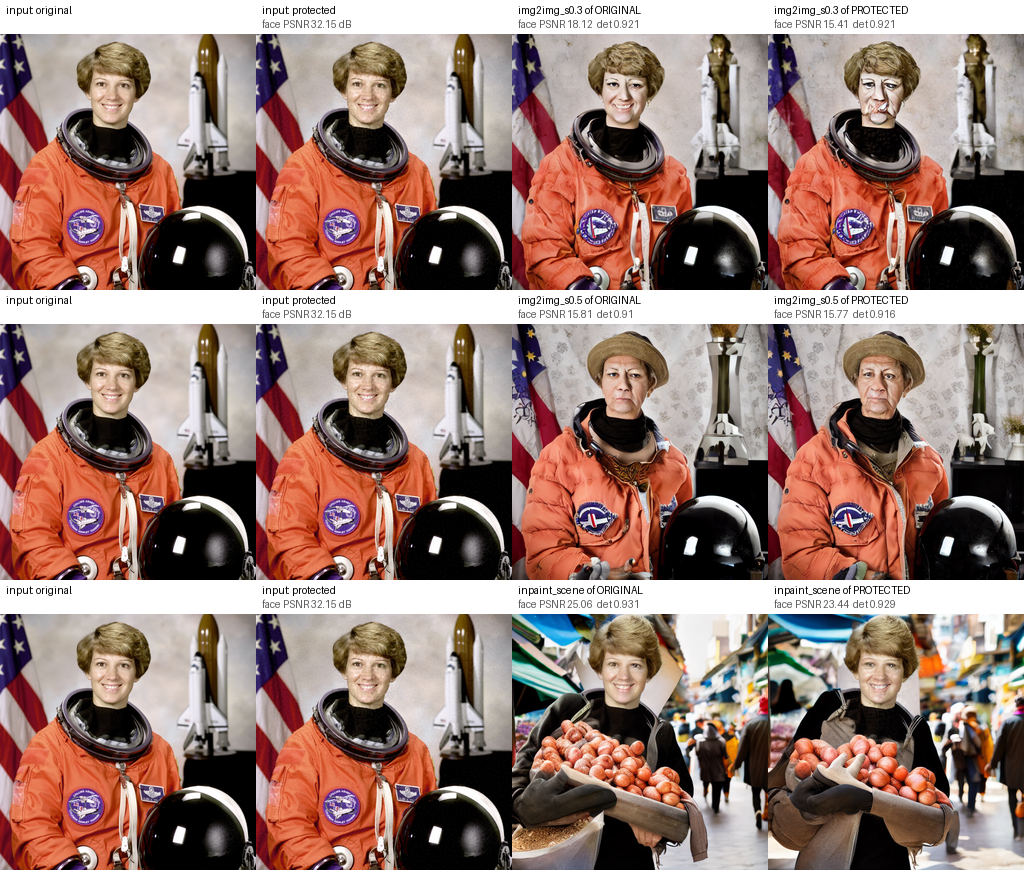

In [5]:
# 5. Show the results
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{OUT}/report.md").read()))
display(Image(f"{OUT}/before_after.png"))
display(Image(f"{OUT}/grid.png"))

In [6]:
# 6. Download everything (figures, edits, report, protected image)
import shutil
from google.colab import files
shutil.make_archive("i3_results", "zip", OUT)
files.download("i3_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Tips
- Re-run cell 4 with different settings and a different `OUT` folder to compare (e.g. `FACE_PSNR = 30`).
- Colab sessions reset after inactivity: download results before you leave.
- Put the numbers from `report.md` into `docs/EXPERIMENTS.md` in your repo.